# What's New Since 0.4.1

This notebook walks through the main changes since the 0.4.1 release on small examples and compares each with what 0.4.1 returned for the same input; the [changelog](https://github.com/cheginit/catsmoothing/blob/main/CHANGELOG.md) lists every change.
The 0.4.1 results come from [`data/make_v041_data.py`](https://github.com/cheginit/catsmoothing/blob/main/docs/examples/data/make_v041_data.py), which runs the released 0.4.1 wheel and saves its outputs to [`data/v041.npz`](https://github.com/cheginit/catsmoothing/raw/main/docs/examples/data/v041.npz); keep that file in a `data` folder next to this notebook.
Where a comparison uses a generated input, the notebook checks it against a copy or a SHA-256 digest saved with those outputs.
Run it with a CatSmoothing release newer than 0.4.1, or with the main branch.

In [1]:
from __future__ import annotations

import hashlib
import inspect
import os
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import shapely
import shapely.plotting
from IPython.display import Markdown

import catsmoothing as cs
from catsmoothing import CatmullRom

if "continuity" not in inspect.signature(CatmullRom).parameters:
    raise RuntimeError("This notebook needs a CatSmoothing release newer than 0.4.1.")

v041 = np.load("data/v041.npz")

A few helpers shared by the sections below:

In [2]:
def noisy_bumps(n_lines, n_vertices, seed):
    """Noisy samples of a Gaussian bump, shape ``(n_lines, n_vertices, 2)``."""
    rng = np.random.default_rng(seed)
    x = np.linspace(-3, 2.5, n_vertices)
    y = np.exp(-(x**2)) + 0.1 * rng.standard_normal((n_lines, n_vertices))
    return np.stack([np.broadcast_to(x, y.shape), y], axis=-1)


def noisy_ring():
    """Return a noisy circle of radius 10 with its first (seam) vertex at radius 12."""
    rng = np.random.default_rng(7)
    theta = np.linspace(0, 2 * np.pi, 61)[:-1]
    radius = 10 + 0.5 * rng.standard_normal(60)
    ring = np.c_[radius * np.cos(theta), radius * np.sin(theta)]
    ring[0] = (12.0, 0.0)
    return ring


def digest(arr):
    """SHA-256 of an array's bytes."""
    return hashlib.sha256(np.ascontiguousarray(arr).tobytes()).hexdigest()


def span_lengths(spline, params, n_sub=1000):
    """Arc length of ``spline`` between consecutive parameter values, from ``n_sub`` chords each."""
    t = np.linspace(params[:-1], params[1:], n_sub, axis=1)
    points = spline.evaluate(t.ravel()).reshape(*t.shape, 2)
    return np.linalg.norm(np.diff(points, axis=1), axis=2).sum(axis=1)


def curvature(spline, t):
    """Signed curvature of ``spline`` at parameter values ``t``."""
    d1, d2 = spline.evaluate(t, 1), spline.evaluate(t, 2)
    return (d1[:, 0] * d2[:, 1] - d1[:, 1] * d2[:, 0]) / np.linalg.norm(d1, axis=1) ** 3


def table(header, rows):
    """Render rows as a Markdown table."""
    lines = ["| " + " | ".join(header) + " |", "|" + " --- |" * len(header)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    return Markdown("\n".join(lines))

## Points spaced by equal arc length

`smooth_linestrings`, `smooth_polygon`, and `CatmullRom.uniform_distances` place points at equal arc length along the spline, using adaptive Gauss-Legendre quadrature for the length and Newton's method to invert it.
0.4.1 tried to equalize the chords between points with a fixed-point iteration capped by `max_iterations`.
The `tolerance` and `max_iterations` arguments of that iteration are now ignored and raise a `DeprecationWarning`.

Below, `CatmullRom.uniform_distances` in each version resamples 200 noisy lines of 100 vertices to 100 points each.
The spread of a line is its longest span divided by its shortest, with each span's length measured along the curve.

In [3]:
bumps = noisy_bumps(200, 100, seed=123)
if digest(bumps) != v041["bumps_digest"]:
    raise ValueError("The noisy lines differ from the ones 0.4.1 resampled.")
splines = [CatmullRom(b, alpha=0.5) for b in bumps]

# Both versions fit the same curve: 0.4.1's points lie on the new spline.
np.testing.assert_allclose(
    splines[0].evaluate(v041["spacing_params"][0]), v041["spacing_points"], atol=1e-9
)

old_spans = [span_lengths(s, p) for s, p in zip(splines, v041["spacing_params"])]
new_params = [s.uniform_distances(100) for s in splines]
new_spans = [span_lengths(s, p) for s, p in zip(splines, new_params)]
old_spread = np.array([s.max() / s.min() for s in old_spans])
new_spread = np.array([s.max() / s.min() for s in new_spans])
table(
    ["Version", "Median spread", "Worst spread"],
    [
        ["0.4.1", f"{np.median(old_spread):.3f}", f"{old_spread.max():.3f}"],
        ["new", f"{np.median(new_spread):.4f}", f"{new_spread.max():.4f}"],
    ],
)

| Version | Median spread | Worst spread |
| --- | --- | --- |
| 0.4.1 | 3.612 | 6.916 |
| new | 1.0000 | 1.0000 |

A line near the median 0.4.1 spread, with both sets of points and the length of every span:

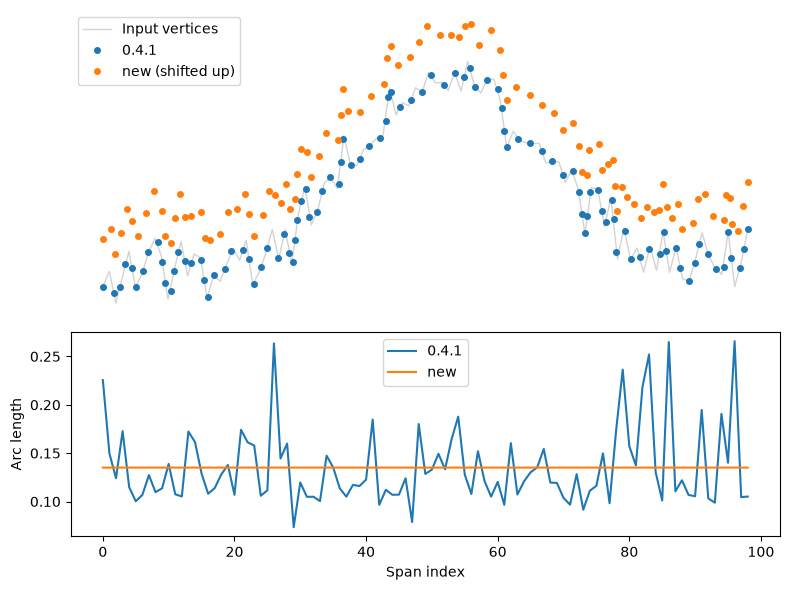

In [4]:
i = int(np.argsort(old_spread)[len(old_spread) // 2])
fig, (ax_line, ax_span) = plt.subplots(2, 1, figsize=(8, 6), height_ratios=(3, 2))
ax_line.plot(*bumps[i].T, color="lightgray", lw=1, label="Input vertices")
ax_line.plot(*splines[i].evaluate(v041["spacing_params"][i]).T, "o", ms=4, label="0.4.1")
shifted = splines[i].evaluate(new_params[i])
shifted[:, 1] += 0.25
ax_line.plot(*shifted.T, "o", ms=4, label="new (shifted up)")
ax_line.legend(loc="upper left")
ax_line.set_axis_off()
ax_span.plot(old_spans[i], label="0.4.1")
ax_span.plot(new_spans[i], label="new")
ax_span.set_xlabel("Span index")
ax_span.set_ylabel("Arc length")
ax_span.legend()
fig.tight_layout()
fig.savefig("images/arc_length.png", bbox_inches="tight", dpi=90)

## `distances` in coordinate units

`distances` (and `distance` in `smooth_polygon`) now caps the gap between output points, measured along the curve in the units of the coordinates: the points are evenly spaced, as few as possible, and no farther apart than the given distance.
0.4.1 compared it with the spline's centripetal parameter, a sum of square roots of chord lengths, and counted intervals as points.
On a straight line 100 units long:

In [5]:
line_100 = np.array([(0, 0), (25, 0), (50, 0), (75, 0), (100, 0)], dtype=float)
np.testing.assert_array_equal(line_100, v041["line_100"])
new_points = shapely.get_coordinates(
    cs.smooth_linestrings(shapely.LineString(line_100), distances=10)
)
old_points = v041["distances_points"]
table(
    ["Version", "Points for `distances=10`", "Largest gap"],
    [
        ["0.4.1", len(old_points), f"{np.diff(old_points[:, 0]).max():g}"],
        ["new", len(new_points), f"{np.diff(new_points[:, 0]).max():g}"],
    ],
)

| Version | Points for `distances=10` | Largest gap |
| --- | --- | --- |
| 0.4.1 | 2 | 100 |
| new | 11 | 10 |

## Gaussian smoothing at line ends and ring seams

Gaussian pre-smoothing needs vertices past each end of an open line.
0.4.1 mirrored the line about its end vertex, which folds a straight run back on itself and drags the vertices near each end along the line.
The new version reflects the line through its end vertex, which extends a straight run, so evenly spaced collinear vertices stay where they are.
Here are 21 evenly spaced vertices on a straight line smoothed with `gaussian_sigma=3`:

| Version | Largest vertex shift | Vertex spacing |
| --- | --- | --- |
| 0.4.1 | 1.682 | 1.118 |
| new | 7.94e-15 | 1.118 |

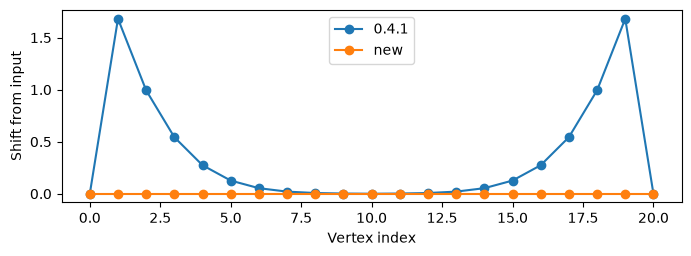

In [6]:
straight = np.c_[np.linspace(0, 20, 21), np.linspace(0, 10, 21)]
np.testing.assert_array_equal(straight, v041["straight"])
spline = CatmullRom(straight, alpha=0.5, gaussian_sigma=3)
old_shift = np.linalg.norm(v041["straight_smoothed"] - straight, axis=1)
new_shift = np.linalg.norm(spline.evaluate(spline.grid) - straight, axis=1)

fig, ax = plt.subplots(figsize=(8, 2.5))
ax.plot(old_shift, "o-", label="0.4.1")
ax.plot(new_shift, "o-", label="new")
ax.set_xlabel("Vertex index")
ax.set_ylabel("Shift from input")
ax.legend()
table(
    ["Version", "Largest vertex shift", "Vertex spacing"],
    [
        ["0.4.1", f"{old_shift.max():.3f}", f"{np.hypot(1, 0.5):.3f}"],
        ["new", f"{new_shift.max():.3g}", f"{np.hypot(1, 0.5):.3f}"],
    ],
)

For a closed ring 0.4.1 kept the first vertex, where the ring starts and ends, fixed, so a stray vertex at the seam survived smoothing.
The new version wraps the kernel around the ring.
This noisy circle of radius 10 has its seam vertex pushed out to radius 12:

| Version | Seam radius after smoothing | Largest radius elsewhere |
| --- | --- | --- |
| 0.4.1 | 12.000 | 10.185 |
| new | 9.800 | 9.835 |

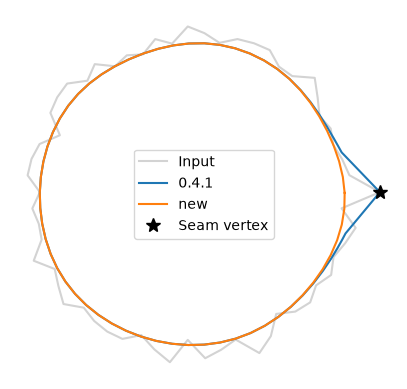

In [7]:
ring = noisy_ring()
np.testing.assert_array_equal(ring, v041["ring"])
spline = CatmullRom(np.vstack([ring, ring[:1]]), alpha=0.5, bc_type="closed", gaussian_sigma=3)
new_ring = spline.evaluate(spline.grid)
old_ring = v041["ring_smoothed"]
old_radius = np.linalg.norm(old_ring, axis=1)
new_radius = np.linalg.norm(new_ring, axis=1)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(*np.vstack([ring, ring[:1]]).T, color="lightgray", label="Input")
ax.plot(*old_ring.T, label="0.4.1")
ax.plot(*new_ring.T, label="new")
ax.plot(*ring[0], "k*", ms=10, label="Seam vertex")
ax.set_aspect("equal")
ax.set_axis_off()
ax.legend(loc="center")
table(
    ["Version", "Seam radius after smoothing", "Largest radius elsewhere"],
    [
        ["0.4.1", f"{old_radius[0]:.3f}", f"{old_radius[1:-1].max():.3f}"],
        ["new", f"{new_radius[0]:.3f}", f"{new_radius[1:-1].max():.3f}"],
    ],
)

## Gaussian sigma in length units

With `sigma_units="vertices"`, the default and the only choice in 0.4.1, sigma counts vertices, so the same sigma reaches farther where vertices are sparse.
`sigma_units="length"` measures sigma in coordinate units along the input line and weights each vertex by the length of line it stands for.
The sine below has a vertex every 0.1 units of x for x < 5 and every 0.5 units after that, and no noise, so any loss in its peaks comes from the smoothing.
Four vertex steps on the dense half cover 0.4 units of x, and a little more along the line where the sine is steep.

| `sigma_units` | sigma | Peak near x = 1.57 (dense) | Peak near x = 7.85 (sparse) |
| --- | --- | --- | --- |
| `vertices` | 4 | 0.9232 | 0.0328 |
| `length` | 0.4 | 0.9304 | 0.9295 |

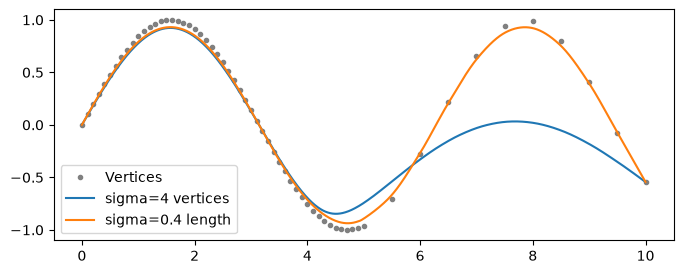

In [8]:
x = np.r_[np.arange(0, 5, 0.1), np.arange(5, 10.01, 0.5)]
sine = np.c_[x, np.sin(x)]

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(*sine.T, ".", color="gray", label="Vertices")
rows = []
for units, sigma in (("vertices", 4), ("length", 0.4)):
    spline = CatmullRom(sine, alpha=0.5, gaussian_sigma=sigma, sigma_units=units)
    curve = spline.evaluate(np.linspace(spline.grid[0], spline.grid[-1], 5000))
    ax.plot(*curve.T, label=f"sigma={sigma} {units}")
    dense_peak = curve[(curve[:, 0] > 0.5) & (curve[:, 0] < 2.6), 1].max()
    sparse_peak = curve[(curve[:, 0] > 6.8) & (curve[:, 0] < 8.9), 1].max()
    rows.append([f"`{units}`", sigma, f"{dense_peak:.4f}", f"{sparse_peak:.4f}"])
ax.legend(loc="lower left")
table(["`sigma_units`", "sigma", "Peak near x = 1.57 (dense)", "Peak near x = 7.85 (sparse)"], rows)

Both sine peaks have height 1.
Counted in vertices, sigma nearly erases the sparse peak; measured in length, both peaks lose nearly the same amount.

## Taubin smoothing

Gaussian smoothing pulls each vertex toward the average of its neighbors, which also shrinks the curve.
`taubin_iterations` alternates a shrinking step (lambda 0.5) with an inflating step (mu -0.53).
Together the two steps damp jitter that changes from vertex to vertex and leave slower bends at about their size.
On a noisy circle of 40 vertices and radius 10:

| Option | Area / true area | Std of radius about the center |
| --- | --- | --- |
| no smoothing | 1.000 | 0.256 |
| gaussian_sigma=2 | 0.906 | 0.080 |
| taubin_iterations=10 | 1.007 | 0.145 |
| taubin_iterations=50 | 1.034 | 0.108 |

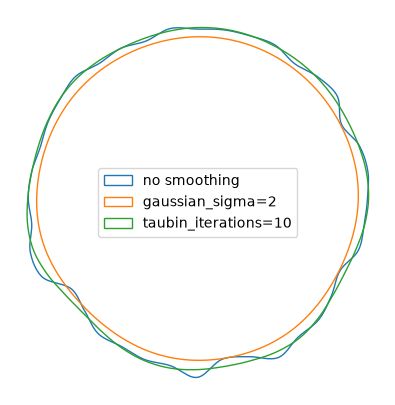

In [9]:
rng = np.random.default_rng(1)
theta = np.linspace(0, 2 * np.pi, 41)[:-1]
radius = 10 + 0.3 * rng.standard_normal(40)
circle = shapely.Polygon(np.c_[radius * np.cos(theta), radius * np.sin(theta)])

options = {
    "no smoothing": {},
    "gaussian_sigma=2": {"gaussian_sigma": 2},
    "taubin_iterations=10": {"taubin_iterations": 10},
    "taubin_iterations=50": {"taubin_iterations": 50},
}
fig, ax = plt.subplots(figsize=(5, 5))
rows = []
for k, (label, kwargs) in enumerate(options.items()):
    smoothed = cs.smooth_polygon(circle, n_pts=400, **kwargs)
    radii = np.linalg.norm(shapely.get_coordinates(smoothed.exterior), axis=1)
    rows.append([label, f"{smoothed.area / (np.pi * 100):.3f}", f"{radii.std():.3f}"])
    if label != "taubin_iterations=50":
        shapely.plotting.plot_polygon(
            smoothed, ax=ax, add_points=False, color=f"C{k}", facecolor="none", label=label
        )
ax.set_aspect("equal")
ax.set_axis_off()
ax.legend(loc="center")
table(["Option", "Area / true area", "Std of radius about the center"], rows)

The Gaussian removes more jitter and shrinks the circle; ten Taubin iterations remove less and keep its area, and fifty start to inflate it.
How a shape fares depends on how many vertices draw each bend.
Clean circles drawn with 8, 16, and 40 vertices, after 10 Taubin iterations:

In [10]:
rows = []
for n_vertices in (8, 16, 40):
    theta = np.linspace(0, 2 * np.pi, n_vertices, endpoint=False)
    clean = shapely.Polygon(np.c_[10 * np.cos(theta), 10 * np.sin(theta)])
    before = cs.smooth_polygon(clean, n_pts=400).area
    after = cs.smooth_polygon(clean, n_pts=400, taubin_iterations=10).area
    rows.append([n_vertices, f"{after / before:.3f}"])
table(["Vertices in the circle", "Area after / before"], rows)

| Vertices in the circle | Area after / before |
| --- | --- |
| 8 | 0.755 |
| 16 | 1.015 |
| 40 | 1.007 |

A circle of 8 vertices still shrinks, since one turn spans too few vertices for the inflating step to make up for the shrinking one, while 16 and 40 vertices keep their area within a few percent.

## G2 and C2 continuity

A Catmull-Rom spline is C1: its tangent is continuous where pieces join, and its curvature can jump at each vertex.
`continuity="g2"` makes the curvature continuous, and `continuity="c2"` also makes the second derivative with respect to the curve parameter continuous.
Both use Yuksel's continuity-enhancing splits (SIGGRAPH 2026), which turn each piece into three cubics and keep every vertex and its tangent.
The table measures each change across a vertex as the difference between the values just after and just before it, 1e-10 apart in the curve parameter.

| `continuity` | Curvature change across a vertex | Second-derivative change across a vertex | Largest gap to the C1 curve at the same parameter | Largest vertex error |
| --- | --- | --- | --- | --- |
| `c1` | 1.5 | 1.56 | 0.0000 | 0 |
| `g2` | 1.17e-09 | 0.981 | 0.0171 | 0 |
| `c2` | 1.2e-09 | 4.17e-10 | 0.0215 | 0 |

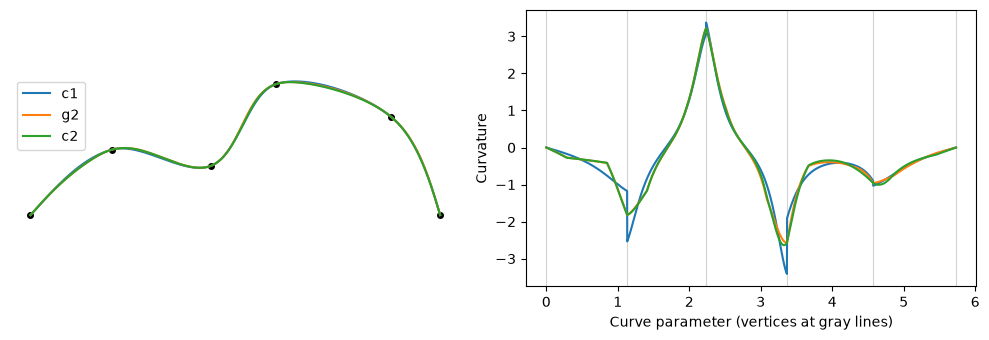

In [11]:
wavy = np.array([(0, 0), (1, 0.8), (2.2, 0.6), (3, 1.6), (4.4, 1.2), (5, 0)], dtype=float)
c1 = CatmullRom(wavy, alpha=0.5)
t = np.linspace(c1.grid[0], c1.grid[-1], 4001)
eps = 1e-10

fig, (ax_shape, ax_curv) = plt.subplots(1, 2, figsize=(10, 3.5))
ax_shape.plot(*wavy.T, "ko", ms=4)
rows = []
for continuity in ("c1", "g2", "c2"):
    spline = CatmullRom(wavy, alpha=0.5, continuity=continuity)
    ax_shape.plot(*spline.evaluate(t).T, label=continuity)
    ax_curv.plot(t, curvature(spline, t), label=continuity)
    inner = spline.grid[1:-1]
    curvature_jump = np.abs(curvature(spline, inner + eps) - curvature(spline, inner - eps)).max()
    d2_jump = np.linalg.norm(
        spline.evaluate(inner + eps, 2) - spline.evaluate(inner - eps, 2), axis=1
    ).max()
    rows.append(
        [
            f"`{continuity}`",
            f"{curvature_jump:.3g}",
            f"{d2_jump:.3g}",
            f"{np.linalg.norm(spline.evaluate(t) - c1.evaluate(t), axis=1).max():.4f}",
            f"{np.linalg.norm(spline.evaluate(spline.grid) - wavy, axis=1).max():.3g}",
        ]
    )
for g in c1.grid:
    ax_curv.axvline(g, color="lightgray", lw=0.8, zorder=0)
ax_shape.set_aspect("equal")
ax_shape.set_axis_off()
ax_shape.legend()
ax_curv.set_xlabel("Curve parameter (vertices at gray lines)")
ax_curv.set_ylabel("Curvature")
fig.tight_layout()
table(
    [
        "`continuity`",
        "Curvature change across a vertex",
        "Second-derivative change across a vertex",
        "Largest gap to the C1 curve at the same parameter",
        "Largest vertex error",
    ],
    rows,
)

The three curves overlap at plotting scale; the table gives how far each strays from the C1 curve.

## Derivatives with respect to the curve parameter

`CatmullRom.evaluate(t, n)` with `n=1` or `n=2` returns derivatives with respect to the curve parameter `t`.
0.4.1 scaled each piece's derivatives by that piece's grid step (and its square for `n=2`), so their size was off on any grid with steps other than 1; their directions, and so tangent angles, were right.
A central difference of positions, 1e-6 apart in `t`, gives the first derivative to compare with:

In [12]:
np.testing.assert_array_equal(wavy, v041["wavy"])
params = np.array([0.3, 1.5, 2.9, 4.0])
np.testing.assert_array_equal(params, v041["derivative_params"])
h = 1e-6
central = (c1.evaluate(params + h) - c1.evaluate(params - h)) / (2 * h)
table(
    ["Version", "Largest error of `evaluate(t, 1)`", "Largest angle error (rad)"],
    [
        [
            name,
            f"{np.linalg.norm(d1 - central, axis=1).max():.3g}",
            f"{np.abs(np.arctan2(d1[:, 1], d1[:, 0]) - np.arctan2(central[:, 1], central[:, 0])).max():.2g}",
        ]
        for name, d1 in (("0.4.1", v041["derivatives"]), ("new", c1.evaluate(params, 1)))
    ],
)

| Version | Largest error of `evaluate(t, 1)` | Largest angle error (rad) |
| --- | --- | --- |
| 0.4.1 | 0.282 | 9e-11 |
| new | 1.55e-10 | 9e-11 |

## Rings close exactly

The last point of a smoothed curve is now the last vertex itself, so a smoothed ring ends exactly on its first point.
In 0.4.1 rounding left the last point a hair away from the first at projected-CRS magnitudes, and shapely closed the ring by appending one more vertex.
The noisy ring from above, scaled to meters, moved to UTM-like coordinates, and smoothed to 100 points:

In [13]:
projected = shapely.Polygon(ring * 1000 + (500_000.0, 4_000_000.0))
new_coords = shapely.get_coordinates(cs.smooth_polygon(projected, n_pts=100))
old_coords = v041["projected_coords"]


def shortest_edge(coords):
    return np.linalg.norm(np.diff(coords, axis=0), axis=1).min()


table(
    ["Version", "Vertices in the exterior", "Shortest edge (m)"],
    [
        ["0.4.1", len(old_coords), f"{shortest_edge(old_coords):.2g}"],
        ["new", len(new_coords), f"{shortest_edge(new_coords):.1f}"],
    ],
)

| Version | Vertices in the exterior | Shortest edge (m) |
| --- | --- | --- |
| 0.4.1 | 101 | 4.7e-10 |
| new | 100 | 592.4 |

## Tangent angles on rings

`linestrings_tangent_angles` fits a `LinearRing` with a periodic spline.
A ring's first and last vertices are the same point, and they now get the same angle; 0.4.1 fitted the ring as an open line and gave two different angles.

In [14]:
new_angles = cs.linestrings_tangent_angles(shapely.LinearRing(ring))
old_angles = v041["ring_angles"]
table(
    ["Version", "Angle at first vertex", "Angle at last vertex"],
    [
        ["0.4.1", f"{old_angles[0]:.4f}", f"{old_angles[-1]:.4f}"],
        ["new", f"{new_angles[0]:.4f}", f"{new_angles[-1]:.4f}"],
    ],
)

| Version | Angle at first vertex | Angle at last vertex |
| --- | --- | --- |
| 0.4.1 | 2.7428 | 0.2429 |
| new | 1.5167 | 1.5167 |

## Invalid and degenerate inputs

Inputs that 0.4.1 turned into NaN coordinates, truncated without a word, accepted in a form it could not use, or failed on with an internal or GEOS error now either work or raise a `ValueError` that names the problem.

In [15]:
def describe(result):
    coords = np.asarray(result)
    if coords.size and np.isnan(coords).all():
        state = "all NaN"
    elif np.isfinite(coords).all():
        state = "all finite"
    else:
        state = "some not finite"
    return f"array of shape {coords.shape}, {state}"


def outcome(func, summary=describe):
    try:
        return summary(func())
    except ValueError as e:
        return f"ValueError: {e}"


def smooth_coords(coords, n_pts=5, **kwargs):
    line = shapely.LineString(coords)
    return shapely.get_coordinates(cs.smooth_linestrings(line, n_pts=n_pts, **kwargs))


def first_param(params):
    return f"starts at {params[0]:g}"


short = np.c_[np.arange(5.0), 2 * np.arange(5.0)]


def largest_shift(points):
    return f"largest vertex shift {np.linalg.norm(points - short, axis=1).max():.3g}"


zigzag = np.array([(0, 0), (1, 1), (2, 0), (3, 1)], dtype=float)
np.testing.assert_array_equal(zigzag, v041["zigzag"])
np.testing.assert_array_equal(short, v041["short"])
short_spline = CatmullRom(short, alpha=0.5, gaussian_sigma=3)
table(
    ["Input", "0.4.1", "new"],
    [
        [
            "Repeated vertex",
            describe(v041["repeated_coords"]),
            outcome(lambda: smooth_coords([(0, 0), (1, 1), (1, 1), (2, 0)])),
        ],
        [
            "Two vertices",
            str(v041["two_vertex_error"]),
            outcome(lambda: smooth_coords([(0, 0), (1, 1)])),
        ],
        [
            "`n_pts=1`",
            str(v041["n_pts_one_error"]),
            outcome(lambda: smooth_coords(line_100, n_pts=1)),
        ],
        [
            "`distances=-1`",
            str(v041["negative_distance_error"]),
            outcome(lambda: smooth_coords(wavy, n_pts=None, distances=-1.0)),
        ],
        [
            "NaN vertex",
            describe(v041["nan_coords"]),
            outcome(lambda: smooth_coords([(0, 0), (1, np.nan), (2, 0)])),
        ],
        [
            "NaN `gaussian_sigmas`",
            describe(v041["nan_sigma_coords"]),
            outcome(lambda: smooth_coords(wavy, gaussian_sigmas=np.nan)),
        ],
        [
            "3D vertices in `CatmullRom`",
            describe(v041["xyz_points"]),
            outcome(lambda: CatmullRom([(0, 0, 1), (1, 1, 2), (2, 0, 3)]).evaluate([0.5])),
        ],
        [
            "Grid not increasing (`grid=[0, 2, 1, 3]`)",
            describe(v041["unsorted_grid_points"]),
            outcome(lambda: CatmullRom(zigzag, grid=[0, 2, 1, 3]).evaluate([0.5])),
        ],
        [
            "`uniform_distances` on `grid=[1, 2, 3, 4]`",
            first_param(v041["offset_grid_params"]),
            outcome(
                lambda: CatmullRom(zigzag, grid=[1, 2, 3, 4]).uniform_distances(5), first_param
            ),
        ],
        [
            "Kernel wider than a 5-vertex straight line",
            largest_shift(v041["short_smoothed"]),
            largest_shift(short_spline.evaluate(short_spline.grid)),
        ],
    ],
)

| Input | 0.4.1 | new |
| --- | --- | --- |
| Repeated vertex | array of shape (5, 2), all NaN | array of shape (5, 2), all finite |
| Two vertices | ValueError: Internal error in tangent calculation | array of shape (5, 2), all finite |
| `n_pts=1` | GEOSException: IllegalArgumentException: point array must contain 0 or >1 elements | ValueError: n_pts must be at least 2 |
| `distances=-1` | GEOSException: IllegalArgumentException: point array must contain 0 or >1 elements | ValueError: distance must be finite and positive |
| NaN vertex | array of shape (5, 2), all NaN | ValueError: Vertices must be finite |
| NaN `gaussian_sigmas` | array of shape (5, 2), all NaN | ValueError: gaussian_sigma must be finite and non-negative |
| 3D vertices in `CatmullRom` | array of shape (1, 2), all finite | ValueError: Vertices must have shape (n, 2), got (n, 3) |
| Grid not increasing (`grid=[0, 2, 1, 3]`) | array of shape (1, 2), all finite | ValueError: Grid must be finite and strictly increasing |
| `uniform_distances` on `grid=[1, 2, 3, 4]` | starts at 0 | starts at 1 |
| Kernel wider than a 5-vertex straight line | largest vertex shift 2.1 | largest vertex shift 4.97e-16 |

## Speed

The spline core stores each piece's cubic coefficients inline and evaluates small lines serially, the bindings release the GIL while Rust works, and all coordinates cross between Python and Rust in one array.
Smoothing 10,000 noisy lines of 100 vertices to 100 points each, timed as 7 calls after one warm-up call, measures all of these together, along with the new spacing algorithm:

In [16]:
timing_bumps = noisy_bumps(10_000, 100, seed=2026)
if digest(timing_bumps) != v041["timing_digest"]:
    raise ValueError("The timing lines differ from the ones 0.4.1 smoothed.")
lines = list(shapely.linestrings(timing_bumps))


def call_times(func, repeat=7):
    func()
    times = []
    for _ in range(repeat):
        start = time.perf_counter()
        func()
        times.append(time.perf_counter() - start)
    return np.array(times)


new_times = call_times(lambda: cs.smooth_linestrings(lines, n_pts=[100] * len(lines)))
old_times = v041["smooth_times"]
machine = (
    f"{platform.platform()}, {os.cpu_count()} CPUs, Python {platform.python_version()}, "
    f"numpy {np.__version__}, shapely {shapely.__version__}"
)
table(
    ["Version", "Fastest (ms)", "Median (ms)", "Machine"],
    [
        [
            "0.4.1",
            f"{old_times.min() * 1e3:.0f}",
            f"{np.median(old_times) * 1e3:.0f}",
            str(v041["machine"]),
        ],
        ["new", f"{new_times.min() * 1e3:.0f}", f"{np.median(new_times) * 1e3:.0f}", machine],
    ],
)

| Version | Fastest (ms) | Median (ms) | Machine |
| --- | --- | --- | --- |
| 0.4.1 | 500 | 542 | macOS-27.0.1-arm64-arm-64bit-Mach-O, 12 CPUs, Python 3.14.9, numpy 2.5.4, shapely 2.2.0, catsmoothing 0.4.1 |
| new | 67 | 68 | macOS-27.0.1-arm64-arm-64bit-Mach-O, 12 CPUs, Python 3.14.9, numpy 2.5.4, shapely 2.2.0 |

The 0.4.1 times were recorded by `data/make_v041_data.py`; to compare on another machine, run that script there and then rerun this notebook from the top.